C:\Users\I\AppData\Local\Temp\ipykernel_9120\3100492248.py:10: DtypeWarning: Columns (0: conf_flag, 1: extent_flag, 2: PS21P_objID, 3: LEG21P_OBJID, 4: SDSS_CLASS, 5: SDSS_SUBCLASS, 6: AGNDB_spec_class, 7: AGNDB_gen_class, 8: AGNDB_SED_class, 9: AGNDB_xray_class, 10: AGNDB_image_class, 11: AGNDB_best_class, 12: xray_agn, 13: optical_agn, 14: IR_agn, 15: z_code_normgal, 16: r_code_normgal, 17: g_code_normgal) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(path)


$1e42<=L_{X}<=1e43: 1918
IR AGN in subset: 272


C:\Users\I\AppData\Local\Temp\ipykernel_9120\3100492248.py:23: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  db_sub['WISE_W1_W2'] = db_sub['WISE_w1mpro'] - db_sub['WISE_w2mpro']
C:\Users\I\AppData\Local\Temp\ipykernel_9120\3100492248.py:24: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  db_sub['WISE_W2_W3'] = db_sub['WISE_w2mpro'] - db_sub['WISE_w3mpro']
C:\Users\I\AppData\Local\Temp\ipykernel_9120\3100492248.py:30: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many time

(-1.15, 3.1)

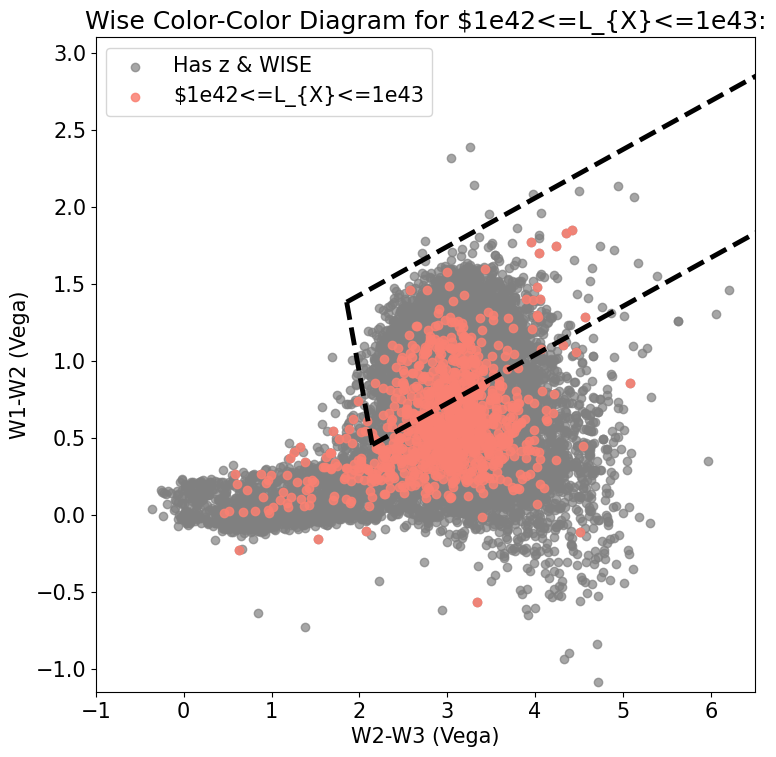

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


plt.figure(figsize=(8.5,8.5))
plt.rcParams.update({'font.size': 15})

path='../data/raw/Multiwave_UMAP_6_26_26.csv'
df = pd.read_csv(path)

df_z_w = df.dropna(subset=['WISE_w1mpro', 'Rec_Z'])

#Define luminosity subset
lum_mask = (df['CSC_b_lum']>=1e42) & (df['CSC_b_lum']<=1e43)
df_sub=df[lum_mask]
print(r'$1e42<=L_{X}<=1e43:', len(df_sub))

'''
These are the WISE magnitudes we subtract to get colors. Colors in astronomy refer to magnitudes or fluxes in two bands being subtracted from each other.
The WISE color-color diagram is in the IR regime.
'''
df_sub['WISE_W1_W2'] = df_sub['WISE_w1mpro'] - df_sub['WISE_w2mpro']
df_sub['WISE_W2_W3'] = df_sub['WISE_w2mpro'] - df_sub['WISE_w3mpro']

x = df_sub['WISE_W2_W3']
y = df_sub['WISE_W1_W2']

#Wedge Boundaries
df_sub['inside_wise_wedge'] = (
    (y <= 0.315*x + 0.796) &
    (y >= 0.315*x - 0.222) &
    (y >= -3.172*x + 7.264)
)


'''
Defining the IR AGN in our subset, I'd recommend doing something like db['lum_sub']=db['name'].isin(db_sub['name']), which will return true if it's 
contained in the subset which makes for easy filtering
'''

dub_sub_ir=df_sub[df_sub['inside_wise_wedge']]
print('IR AGN in subset:', len(dub_sub_ir))

#Physical boundaries of the wedge, easier to plot the endpoints than the actual function
plt.plot([1.855, 8.587], [1.380, 3.501], c='black', linestyle='--', linewidth=3.5)
plt.plot([2.147, 8.587], [0.454, 2.483], c='black', linestyle='--', linewidth=3.5)
plt.plot([1.855, 2.147], [1.380, 0.454], c='black', linestyle='--', linewidth=3.5)


plt.scatter(df_z_w['WISE_w2mpro']-df_z_w['WISE_w3mpro'], df_z_w['WISE_w1mpro']-df_z_w['WISE_w2mpro'], color='gray', alpha=0.7, label='Has z & WISE')
plt.scatter(x, y, color='salmon', alpha=0.85, label=(r'$1e42<=L_{X}<=1e43'))
plt.xlabel('W2-W3 (Vega)')
plt.ylabel('W1-W2 (Vega)')
plt.title('Wise Color-Color Diagram for ' + r'$1e42<=L_{X}<=1e43:')
plt.legend(loc='upper left')
plt.xlim(-1, 6.5)
plt.ylim(-1.15, 3.1)